<a href="https://colab.research.google.com/github/Campelomiranda/projetoanoletivo/blob/claude%2Fvisual-schema-interaction-8irhhq/CityLens_rodar_no_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CityLens · Sorocaba — Pipeline no Google Colab

**Como usar (não precisa instalar nada no seu PC):**
1. No menu de cima: **Ambiente de execução → Executar tudo** (ou `Ctrl+F9`).
2. Espere ~2–4 min. No fim aparece o **mapa das 6 zonas** e uma tabela.

Este notebook baixa a malha de setores censitários do **IBGE** (via `geobr`),
descobre a posição de cada bairro pelo **OpenStreetMap** e atribui cada setor à
**zona do bairro mais próximo**. As 6 zonas são as oficiais do zoneamento da
Prefeitura/Urbes. Regra do projeto: **não inventar dado** — bairro que não for
encontrado é avisado e ignorado, nunca chutado.

No final (**passo 3**) ele ainda baixa do OpenStreetMap os pontos reais de **ônibus, saúde, escolas, mercados/farmácias e parques**, conta por zona e calcula uma **nota 0–100 por zona** (comparando as zonas entre si). Continua valendo **não inventar dado**: categoria sem ponto vira 0 real, nunca chute.


In [1]:
# 1) Instala as bibliotecas (só nesta sessão do Colab)
!pip -q install geobr geopandas osmnx matplotlib requests 2>/dev/null
print("Bibliotecas prontas.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 38.2 MB/s eta 0:00:00
Bibliotecas prontas.


In [2]:
# 2) As 6 zonas oficiais e seus bairros (transcritos do mapa oficial)
ZONAS = {
    "centro": {
        "nome": "Centro",
        "bairros": [
            "Centro"
        ]
    },
    "norte": {
        "nome": "Zona Norte",
        "bairros": [
            "Jardim Botucatu",
            "Jardim Maria Eugênia",
            "Parque Laranjeiras",
            "Jardim Guaíba",
            "Jardim São Guilherme",
            "Jardim Santa Marina",
            "Parque São Bento",
            "Jardim Novo Horizonte",
            "Jardim Maria Antônia Prado",
            "Jardim Guadalupe",
            "Vila Nova Sorocaba",
            "Vila Angélica",
            "Jardim Húngaros",
            "Jardim Brasilândia",
            "Vila Fiori",
            "Jardim Maria do Carmo",
            "Vila Gabriel",
            "Vila Progresso",
            "Vila Porto",
            "Parque Vitória Régia",
            "Retiro São João",
            "Jardim Iguatemi",
            "Jardim Morumbi",
            "Jardim Leocádia",
            "Vila Cardoso",
            "Vila Barão",
            "Vila Nova Esperança",
            "Jardim Zulmira",
            "Santa Terezinha",
            "Vila Trujillo",
            "Vila Carvalho",
            "Vila Santana",
            "Jardim Santa Rosália"
        ]
    },
    "oeste": {
        "nome": "Zona Oeste",
        "bairros": [
            "Jardim Santa Bárbara",
            "Júlio de Mesquita Filho",
            "Jardim Wanel Ville",
            "Parque Esmeralda",
            "Jardim Ouro Fino",
            "Parque Ouro Fino",
            "Parque Manchester",
            "Central Parque",
            "Largo do Divino",
            "Jardim São Paulo",
            "Vila Rica",
            "Jardim Simus",
            "Jardim Vera Cruz"
        ]
    },
    "sul": {
        "nome": "Zona Sul",
        "bairros": [
            "Vila Jardini",
            "Jardim Magnólia",
            "Jardim Paulistano",
            "Jardim Europa",
            "Jardim dos Estados",
            "Jardim América",
            "Jardim Portal da Colina",
            "Jardim Emília",
            "Jardim Sandra",
            "Parque da Biquinha",
            "Vila Assis",
            "Parque Água Vermelha",
            "Jardim Guadalajara",
            "Jardim São Carlos",
            "Parque Campolim"
        ]
    },
    "leste": {
        "nome": "Zona Leste",
        "bairros": [
            "Jardim Gonçalves",
            "Jardim Sol",
            "Jardim Bandeirantes",
            "Jardim Piratininga",
            "Jardim Granja",
            "Vila Haro",
            "Parque Três Meninos",
            "Vila Hortência",
            "Jardim Gutierres",
            "Jardim Prestes de Barros",
            "Vila Colorau",
            "Vila Barcelona",
            "Jardim Parada do Alto"
        ]
    },
    "industrial": {
        "nome": "Zona Industrial",
        "bairros": [
            "Aparecidinha",
            "Brigadeiro Tobias",
            "Alto da Boa Vista",
            "Parque Chico Mendes"
        ]
    }
}

import math, time, json, requests

def dist_km(lon1, lat1, lon2, lat2):
    """Distância aproximada (equiretangular) em km — ótima em escala de cidade."""
    R = 6371.0
    x = math.radians(lon2 - lon1) * math.cos(math.radians((lat1 + lat2)/2))
    y = math.radians(lat2 - lat1)
    return R * math.hypot(x, y)

def atribuir_por_proximidade(setores_xy, pontos):
    """Cada setor (id, lon, lat) recebe a zona do bairro mais próximo."""
    out = []
    for sid, slon, slat in setores_xy:
        melhor = None
        for zona, bairro, blon, blat in pontos:
            d = dist_km(slon, slat, blon, blat)
            if melhor is None or d < melhor[0]:
                melhor = (d, zona, bairro)
        out.append({"id": sid, "zona": melhor[1], "bairro": melhor[2],
                    "dist_km": round(melhor[0], 3)})
    return out

print("Funções de recorte carregadas.")

Funções de recorte carregadas.


In [3]:
# 3) Baixa a malha de setores censitários de Sorocaba (IBGE, via geobr)
import geobr, warnings
warnings.filterwarnings("ignore")
COD_SOROCABA = 3552205
try:
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022,
                                      simplified=False, showProgress=False)
except TypeError:
    # versões diferentes do geobr usam nomes de parâmetro distintos
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022)
setores = setores.to_crs(4326)
col_id = next((c for c in ["code_tract","CD_SETOR","CD_GEOCODI"] if c in setores.columns),
              setores.columns[0])
setores["CD_SETOR"] = setores[col_id].astype(str)
print(f"Setores de Sorocaba: {len(setores):,}")
setores.head(3)

censustracts_2022_simplified.parquet: 100%|██████████| 381M/381M [00:10<00:00, 36.7MB/s]


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Setores de Sorocaba: 1,148


,code_tract,code_muni,name_muni,code_neighborhood,name_neighborhood,code_district,name_district,code_subdistrict,name_subdistrict,code_weighting,zone,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,CD_SETOR
0,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.4558 -23.4985, -47.4569 -2...",355220505000001.0
1,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45252 -23.50157, -47.45274...",355220505000002.0
2,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45667 -23.49986, -47.45878...",355220505000003.0


In [4]:
# 4) Descobre a posição (lat/lon) de cada bairro pelo OpenStreetMap (Nominatim)
#    Regras (não inventar dado):
#    (a) só vale resultado DENTRO do contorno de Sorocaba (união dos setores do IBGE);
#    (b) o NOME no OSM tem que bater com o bairro, ignorando "Jardim/Vila/Parque", "de/da" e
#        numerais (ex.: "Jardim Simus II" = "Jardim Simus"); parque só se o Nominatim o reconhecer;
#    (c) tem que ser bairro (suburb/neighbourhood/...) ou parque homônimo — obra, igreja, loja: não;
#    (d) nome que casa com bairros DIFERENTES (ex.: "Jardim Granja" -> Granja Olga e Granja Deolinda)
#        é ambíguo e fica de fora.
#    Qualquer regra falhou -> bairro ignorado e avisado.
import re, unicodedata
from shapely.geometry import Point
CONTORNO = setores.geometry.union_all() if hasattr(setores.geometry, "union_all") else setores.unary_union
TIPOS_BAIRRO = {"suburb", "neighbourhood", "quarter", "city_block", "residential", "hamlet", "village"}
ACEITOS = TIPOS_BAIRRO | {"park"}

# Grafia usada no OpenStreetMap quando difere da lista acima (conferido no OSM)
NOME_NO_OSM = {
    "Jardim Húngaros": "Jardim Hungarês",
    "Jardim Sol": "Jardim do Sol",
    "Jardim Gutierres": "Jardim João Gutierres",  # único "Gutierres" no OSM; fica na Zona Leste
}

def norm(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", s)).strip()

GENERICOS = {"jardim", "jd", "vila", "parque", "conjunto", "habitacional", "residencial",
             "bairro", "loteamento", "gleba", "bleba", "chacara", "chacaras", "recanto", "nucleo",
             "da", "das", "de", "do", "dos", "e", "i", "ii", "iii", "iv", "v", "vi", "vii", "viii"}

def nucleo(s):
    """Palavras que identificam o bairro (sem 'Jardim', 'Vila', 'de', numerais, letras soltas)."""
    return {t for t in norm(s).split() if t not in GENERICOS and len(t) > 1 and not t.isdigit()}

CACHE = "/content/geocode_bairros_v3.json"   # guarda os resultados brutos (dentro do contorno)
try:
    cache = json.load(open(CACHE, encoding="utf-8"))
except Exception:
    cache = {}
headers = {"User-Agent": "CityLens-Sorocaba/1.0 (projeto escolar)"}

def buscar(nome):
    if nome not in cache:
        r = requests.get("https://nominatim.openstreetmap.org/search",
                         params={"q": f"{nome}, Sorocaba, SP, Brasil", "format": "jsonv2",
                                 "limit": 10, "countrycodes": "br"},
                         headers=headers, timeout=25)
        cache[nome] = [{"lon": float(x["lon"]), "lat": float(x["lat"]),
                        "tipo": x.get("addresstype") or x.get("type"),
                        "nome": x.get("name") or x["display_name"].split(",")[0]}
                       for x in r.json()
                       if CONTORNO.contains(Point(float(x["lon"]), float(x["lat"])))]
        json.dump(cache, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)
        time.sleep(1.1)  # política do Nominatim: no máx. 1 pedido por segundo
    return cache[nome]

def localizar(bairro):
    """Devolve ((lon, lat), None) ou (None, motivo)."""
    alvo = NOME_NO_OSM.get(bairro, bairro)
    try:
        res = buscar(alvo)
    except Exception as e:
        return None, f"erro de rede ({e})"
    alvo_nuc = nucleo(alvo)
    # (b) mesmo núcleo de nome: "Parque das Laranjeiras" = "Parque Laranjeiras",
    #     "Jardim Morumbi I e II" = "Jardim Morumbi"; mas "Granja Olga" != "Granja"
    cands = [r for r in res if r["tipo"] in ACEITOS and nucleo(r["nome"]) == alvo_nuc]
    # parque que o próprio Nominatim reconheceu pelo nome alternativo (1º resultado)
    via_parque = None
    if not cands and res and res[0]["tipo"] == "park":
        cands, via_parque = [res[0]], res[0]["nome"]
    if not cands:
        parecidos = sorted({r["nome"] for r in res if alvo_nuc and alvo_nuc <= nucleo(r["nome"])})
        if len(parecidos) > 1:
            return None, "ambíguo no OSM: " + " / ".join(parecidos[:4])
        return None, "não achado como bairro no OSM" + (f" (achou só: {parecidos[0]})" if parecidos else "")
    cands.sort(key=lambda r: r["tipo"] not in TIPOS_BAIRRO)   # bairro antes de parque
    if via_parque:
        PARQUES.append((bairro, via_parque))
    return (cands[0]["lon"], cands[0]["lat"]), None

PARQUES = []

pontos, faltas = [], []
for zona, z in ZONAS.items():
    for bairro in z["bairros"]:
        coord, motivo = localizar(bairro)
        if coord:
            pontos.append((zona, bairro, coord[0], coord[1]))
        else:
            faltas.append((zona, bairro, motivo))

print(f"Bairros localizados: {len(pontos)} | ignorados: {len(faltas)}")
for z, b, m in faltas:
    print(f"  - {b} [{ZONAS[z]['nome']}]: {m}")
if PARQUES:
    print("Localizados pelo parque homônimo:", ", ".join(f"{b} ({p})" for b, p in PARQUES))
if NOME_NO_OSM:
    print("Grafias corrigidas p/ o OSM:", ", ".join(f"{a} -> {b}" for a, b in NOME_NO_OSM.items()))
zonas_com_ponto = {p[0] for p in pontos}
vazias = [ZONAS[z]["nome"] for z in ZONAS if z not in zonas_com_ponto]
assert not vazias, f"Zona sem nenhum bairro localizado: {vazias} — confira os nomes."

Bairros localizados: 73 | ignorados: 6
  - Vila Porto [Zona Norte]: não achado como bairro no OSM (achou só: Vila Porto Rico)
  - Jardim Iguatemi [Zona Norte]: não achado como bairro no OSM
  - Vila Cardoso [Zona Norte]: não achado como bairro no OSM
  - Vila Trujillo [Zona Norte]: não achado como bairro no OSM
  - Jardim Magnólia [Zona Sul]: não achado como bairro no OSM
  - Jardim Granja [Zona Leste]: ambíguo no OSM: Jardim Granja Deolinda / Jardim Granja Olga II / Jardim Granja Olga III / Residencial Granja Olga I
Localizados pelo parque homônimo: Parque da Biquinha (Parque Ecológico Municipal Zila Sisternas Fiorenzo – da Biquinha), Parque Água Vermelha (Parque Natural João Câncio Pereira)
Grafias corrigidas p/ o OSM: Jardim Húngaros -> Jardim Hungarês, Jardim Sol -> Jardim do Sol, Jardim Gutierres -> Jardim João Gutierres


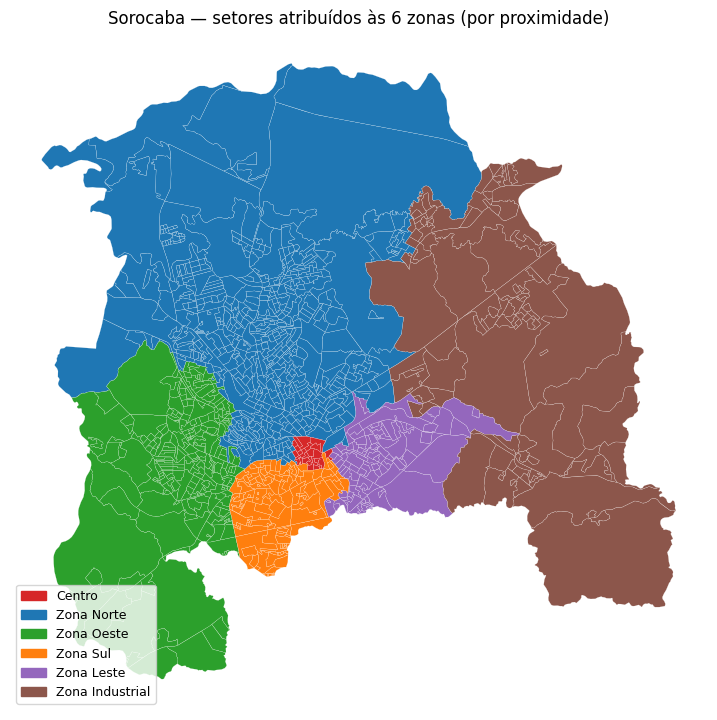


Setores por zona:
  Centro              24
  Zona Norte         543
  Zona Oeste         240
  Zona Sul           127
  Zona Leste         105
  Zona Industrial    109

CSV salvo em /content/setores_por_zona.csv


In [5]:
# 5) Atribui cada setor à sua zona e desenha o mapa
cent = setores.to_crs(3857).geometry.centroid.to_crs(4326)
setores_xy = [(cd, p.x, p.y) for cd, p in zip(setores["CD_SETOR"], cent)]
atrib = atribuir_por_proximidade(setores_xy, pontos)

zona_de = {a["id"]: a["zona"] for a in atrib}
ordem = list(ZONAS.keys())
setores["zona"] = setores["CD_SETOR"].map(zona_de)
setores["_zi"] = setores["zona"].map({z: i for i, z in enumerate(ordem)})

import matplotlib.pyplot as plt, matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(9, 9))
# cores fixas por zona: a mesma cor no mapa e na legenda
CORES = {"centro": "#d62728", "norte": "#1f77b4", "oeste": "#2ca02c",
         "sul": "#ff7f0e", "leste": "#9467bd", "industrial": "#8c564b"}
setores.plot(color=setores["zona"].map(CORES).fillna("#cccccc"),
             linewidth=0.12, edgecolor="white", ax=ax)
ax.legend(handles=[mpatches.Patch(color=CORES[z], label=ZONAS[z]["nome"])
                   for z in ordem],
          loc="lower left", fontsize=9, frameon=True)
ax.set_title("Sorocaba — setores atribuídos às 6 zonas (por proximidade)")
ax.set_axis_off(); plt.show()

# tabela: quantos setores por zona
from collections import Counter
c = Counter(a["zona"] for a in atrib)
print("\nSetores por zona:")
for z in ordem:
    print(f"  {ZONAS[z]['nome']:<16} {c.get(z,0):>5}")

# salva o CSV (baixe pelo painel de Arquivos à esquerda, se quiser)
import csv
with open("/content/setores_por_zona.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f); w.writerow(["CD_SETOR","zona","bairro_mais_proximo","dist_km"])
    for a in atrib: w.writerow([a["id"], a["zona"], a["bairro"], a["dist_km"]])
print("\nCSV salvo em /content/setores_por_zona.csv")

## Passo 3 — dados reais do OpenStreetMap → nota por zona

Agora saímos dos números ilustrativos. As células abaixo baixam do
**OpenStreetMap** os pontos reais de **ônibus, saúde, escolas,
mercados/farmácias e parques**, contam quantos caem em cada zona e transformam
isso numa **nota de 0 a 100** por zona.

Como a nota é calculada (igual ao site): para cada indicador, comparamos as 6
zonas entre si — a que tem **menos** fica perto de 0, a que tem **mais** fica
perto de 100 (normalização min–máx). Depois juntamos:
- **Serviços** = média de saúde + escolas + comércio (por km²)
- **Mobilidade** = pontos de ônibus por km²
- **Meio ambiente** = % da área da zona coberta por parques

> A *caminhabilidade* (4º eixo do site) precisa da malha de ruas e fica para um
> próximo passo — por isso o índice aqui usa 3 eixos. É uma leitura **relativa**
> (entre as zonas de Sorocaba), não uma nota absoluta.

In [6]:
# 6) Passo 3 — baixa os pontos reais do OpenStreetMap e conta por zona
import osmnx as ox, geopandas as gpd
from collections import Counter

# contorno de Sorocaba (união dos setores) para consultar o OSM só na cidade
SORO_POLY = (setores.geometry.union_all() if hasattr(setores.geometry, "union_all")
             else setores.geometry.unary_union)

# o que buscar em cada categoria (tags do OpenStreetMap)
CATEGORIAS = {
    "saude":    {"amenity": ["hospital", "clinic", "doctors"], "healthcare": True},
    "escolas":  {"amenity": ["school", "kindergarten"]},
    "comercio": {"shop": ["supermarket", "convenience", "greengrocer", "bakery"],
                 "amenity": ["pharmacy", "marketplace"]},
    "onibus":   {"highway": "bus_stop"},
    "parques":  {"leisure": ["park", "garden", "nature_reserve"],
                 "landuse": ["recreation_ground"]},
}

def baixar_osm(tags):
    """Baixa feições do OSM dentro de Sorocaba. Se não achar nada, devolve vazio."""
    try:
        g = ox.features_from_polygon(SORO_POLY, tags)      # osmnx >= 1.9
    except AttributeError:
        try:
            g = ox.geometries_from_polygon(SORO_POLY, tags)  # osmnx antigo
        except Exception:
            return gpd.GeoDataFrame(geometry=[], crs=4326)
    except Exception:
        return gpd.GeoDataFrame(geometry=[], crs=4326)
    try:
        return g.to_crs(4326)
    except Exception:
        return g

setores_z = setores[["zona", "geometry"]].copy()
contagem = {z: {} for z in ordem}
gdfs = {}
print("Baixando do OpenStreetMap (pode levar 1–3 min):")
for cat, tags in CATEGORIAS.items():
    g = baixar_osm(tags)
    gdfs[cat] = g
    if len(g) == 0:
        for z in ordem: contagem[z][cat] = 0
        print(f"  {cat:9s}:     0 no OSM")
        continue
    pts = g[["geometry"]].copy()
    pts["geometry"] = pts.geometry.representative_point()   # 1 ponto dentro de cada feição
    j = gpd.sjoin(pts, setores_z, predicate="within", how="inner")
    cc = Counter(j["zona"])
    for z in ordem: contagem[z][cat] = int(cc.get(z, 0))
    print(f"  {cat:9s}: {len(g):>5} no OSM · {len(j):>5} dentro de alguma zona")
print("\nContagem por zona pronta.")

Baixando do OpenStreetMap (pode levar 1–3 min):
  saude    :   286 no OSM ·   286 dentro de alguma zona
  escolas  :   331 no OSM ·   330 dentro de alguma zona
  comercio :   352 no OSM ·   351 dentro de alguma zona
  onibus   :  1978 no OSM ·  1992 dentro de alguma zona
  parques  :  1278 no OSM ·  1280 dentro de alguma zona

Contagem por zona pronta.


Indicadores reais por zona (contagens) e notas 0–100:

           zona  area_km2  saude  escolas  comercio  onibus  verde_pct  servicos  mobilidade  ambiente  indice
         Centro       1.7     42       10        20      58        8.5     100.0       100.0     100.0   100.0
       Zona Sul      16.2     50       44        39     164        4.1      25.0        25.8      34.2    28.3
     Zona Leste      24.2     22       25        22     160        2.4       7.8        15.0       8.6    10.5
     Zona Norte     191.5    124      165       193    1015        2.6       6.7        10.9      11.3     9.6
     Zona Oeste      80.3     31       53        51     352        1.9       4.1         8.0       0.0     4.1
Zona Industrial     135.7     17       33        26     243        2.0       0.0         0.0       2.8     0.9


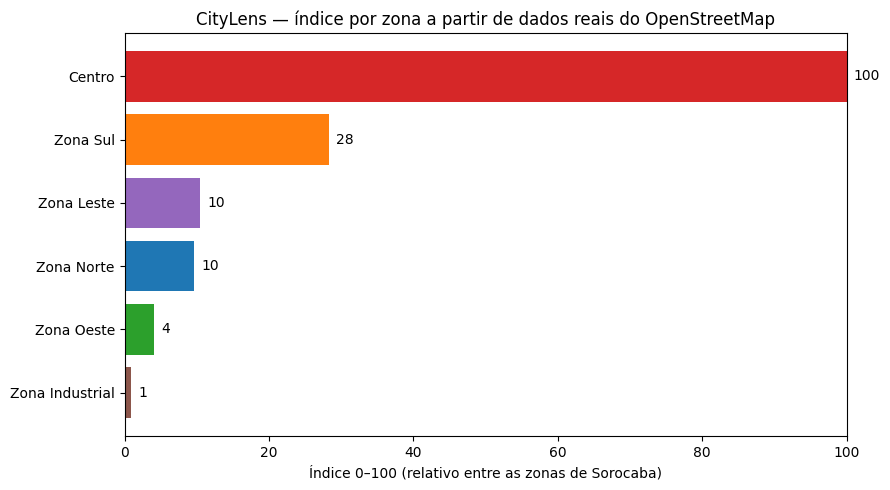


CSV salvo em /content/indicadores_por_zona.csv
Obs: nota RELATIVA (min–máx entre as 6 zonas). A 'caminhabilidade' (4º eixo)
precisa da malha de ruas e fica para o próximo passo — por isso o índice usa 3 eixos.


In [7]:
# 7) Passo 3 — calcula a NOTA por zona (0–100) a partir dos pontos reais
import pandas as pd, numpy as np, matplotlib.pyplot as plt

# área de cada zona em km² (CRS métrico UTM 23S / SIRGAS 2000)
setores_m = setores.to_crs(31983)
area_zona = (setores_m.dissolve(by="zona").geometry.area / 1e6).to_dict()

# % de área verde: soma da área dos parques atribuída à zona do ponto do parque
parque_area = {z: 0.0 for z in ordem}
pk = gdfs.get("parques")
if pk is not None and len(pk):
    pk = pk.to_crs(31983)
    pk = pk[pk.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    if len(pk):
        pk["a_km2"] = pk.geometry.area / 1e6
        rep = gpd.GeoDataFrame(pk[["a_km2"]],
                               geometry=pk.geometry.representative_point(),
                               crs=31983).to_crs(4326)
        jj = gpd.sjoin(rep, setores[["zona", "geometry"]], predicate="within", how="inner")
        for z, sub in jj.groupby("zona"):
            parque_area[z] = float(sub["a_km2"].sum())

# tabela de densidades por zona
rows = []
for z in ordem:
    A = area_zona.get(z, np.nan); n = contagem[z]
    rows.append({"_z": z, "zona": ZONAS[z]["nome"], "area_km2": A,
                 "saude": n["saude"], "escolas": n["escolas"], "comercio": n["comercio"],
                 "onibus": n["onibus"], "parques": n["parques"],
                 "saude_km2": n["saude"]/A, "escolas_km2": n["escolas"]/A,
                 "comercio_km2": n["comercio"]/A, "onibus_km2": n["onibus"]/A,
                 "verde_pct": 100*parque_area[z]/A})
df = pd.DataFrame(rows)

def norm(col):
    v = df[col].astype(float); lo, hi = v.min(), v.max()
    return (v - lo)/(hi - lo)*100 if hi > lo else pd.Series([50.0]*len(v), index=v.index)

df["n_saude"], df["n_escolas"], df["n_comercio"] = norm("saude_km2"), norm("escolas_km2"), norm("comercio_km2")
df["servicos"]   = (df["n_saude"] + df["n_escolas"] + df["n_comercio"]) / 3
df["mobilidade"] = norm("onibus_km2")
df["ambiente"]   = norm("verde_pct")
df["indice"]     = df[["servicos", "mobilidade", "ambiente"]].mean(axis=1)
df = df.sort_values("indice", ascending=False).reset_index(drop=True)

print("Indicadores reais por zona (contagens) e notas 0–100:\n")
cols = ["zona","area_km2","saude","escolas","comercio","onibus","verde_pct",
        "servicos","mobilidade","ambiente","indice"]
print(df[cols].round(1).to_string(index=False))
df.to_csv("/content/indicadores_por_zona.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(df["zona"], df["indice"], color=[CORES[z] for z in df["_z"]])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Índice 0–100 (relativo entre as zonas de Sorocaba)")
ax.set_title("CityLens — índice por zona a partir de dados reais do OpenStreetMap")
for i, v in enumerate(df["indice"]): ax.text(v + 1, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

print("\nCSV salvo em /content/indicadores_por_zona.csv")
print("Obs: nota RELATIVA (min–máx entre as 6 zonas). A 'caminhabilidade' (4º eixo)")
print("precisa da malha de ruas e fica para o próximo passo — por isso o índice usa 3 eixos.")

Indicadores reais por zona — normalizados POR SETOR censitário — e notas 0–100:

           zona  setores  area_km2  saude_set  escolas_set  comercio_set  onibus_set  verde_m2_set  servicos  mobilidade  ambiente  indice
         Centro       24      1.71       1.75         0.42          0.83        2.42       6057.83    100.00      100.00      3.85   67.95
Zona Industrial      109    135.73       0.16         0.30          0.24        2.23      25379.06     16.04       83.36    100.00   66.47
     Zona Norte      543    191.47       0.23         0.30          0.36        1.87       9199.67     23.97       51.35     19.48   31.60
       Zona Sul      127     16.23       0.39         0.35          0.31        1.29       5284.91     32.04        0.00      0.00   10.68
     Zona Leste      105     24.20       0.21         0.24          0.21        1.52       5598.66      4.59       20.66      1.56    8.94
     Zona Oeste      240     80.30       0.13         0.22          0.21        1.47 

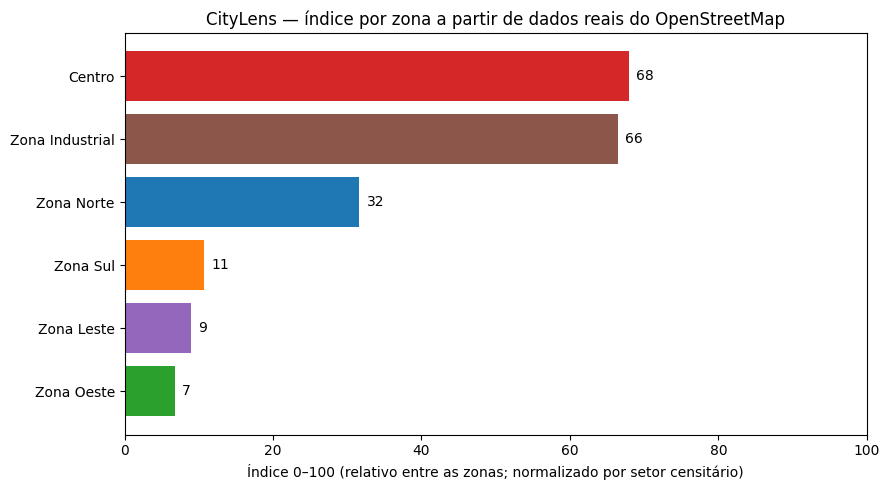


CSV salvo em /content/indicadores_por_zona.csv
Obs: nota RELATIVA (min–máx entre as 6 zonas), por setor censitário (≈ por habitante).
A 'caminhabilidade' (4º eixo) precisa da malha de ruas e fica para o próximo passo.


In [9]:
# 7) Passo 3 — calcula a NOTA por zona (0–100) a partir dos pontos reais
# Normalização POR SETOR CENSITÁRIO (não por km²): os setores do IBGE têm população
# parecida, então "pontos por setor" ≈ "pontos por habitante" — mede acesso real e
# não pune as zonas grandes que têm muito vazio/rural (Norte, Industrial).
import pandas as pd, numpy as np, matplotlib.pyplot as plt

n_setores = setores["zona"].value_counts().to_dict()

# área de cada zona em km² (só informativo; não entra mais na nota)
setores_m = setores.to_crs(31983)
area_zona = (setores_m.dissolve(by="zona").geometry.area / 1e6).to_dict()

# área verde: soma da área dos parques atribuída à zona do ponto do parque
parque_area = {z: 0.0 for z in ordem}
pk = gdfs.get("parques")
if pk is not None and len(pk):
    pk = pk.to_crs(31983)
    pk = pk[pk.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    if len(pk):
        pk["a_km2"] = pk.geometry.area / 1e6
        rep = gpd.GeoDataFrame(pk[["a_km2"]],
                               geometry=pk.geometry.representative_point(),
                               crs=31983).to_crs(4326)
        jj = gpd.sjoin(rep, setores[["zona", "geometry"]], predicate="within", how="inner")
        for z, sub in jj.groupby("zona"):
            parque_area[z] = float(sub["a_km2"].sum())

rows = []
for z in ordem:
    S = n_setores.get(z, 0) or np.nan
    n = contagem[z]
    rows.append({"_z": z, "zona": ZONAS[z]["nome"], "setores": n_setores.get(z, 0),
                 "area_km2": area_zona.get(z, np.nan),
                 "saude": n["saude"], "escolas": n["escolas"], "comercio": n["comercio"],
                 "onibus": n["onibus"],
                 "saude_set": n["saude"]/S, "escolas_set": n["escolas"]/S,
                 "comercio_set": n["comercio"]/S, "onibus_set": n["onibus"]/S,
                 "verde_m2_set": parque_area[z]*1e6/S})
df = pd.DataFrame(rows)

def norm(col):
    v = df[col].astype(float); lo, hi = v.min(), v.max()
    return (v - lo)/(hi - lo)*100 if hi > lo else pd.Series([50.0]*len(v), index=v.index)

df["n_saude"], df["n_escolas"], df["n_comercio"] = norm("saude_set"), norm("escolas_set"), norm("comercio_set")
df["servicos"] = (df["n_saude"] + df["n_escolas"] + df["n_comercio"]) / 3
df["mobilidade"] = norm("onibus_set")
df["ambiente"] = norm("verde_m2_set")
df["indice"] = df[["servicos", "mobilidade", "ambiente"]].mean(axis=1)
df = df.sort_values("indice", ascending=False).reset_index(drop=True)

print("Indicadores reais por zona — normalizados POR SETOR censitário — e notas 0–100:\n")
cols = ["zona", "setores", "area_km2", "saude_set", "escolas_set", "comercio_set",
        "onibus_set", "verde_m2_set", "servicos", "mobilidade", "ambiente", "indice"]
print(df[cols].round(2).to_string(index=False))
df.to_csv("/content/indicadores_por_zona.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(df["zona"], df["indice"], color=[CORES[z] for z in df["_z"]])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Índice 0–100 (relativo entre as zonas; normalizado por setor censitário)")
ax.set_title("CityLens — índice por zona a partir de dados reais do OpenStreetMap")
for i, v in enumerate(df["indice"]): ax.text(v + 1, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

print("\nCSV salvo em /content/indicadores_por_zona.csv")
print("Obs: nota RELATIVA (min–máx entre as 6 zonas), por setor censitário (≈ por habitante).")
print("A 'caminhabilidade' (4º eixo) precisa da malha de ruas e fica para o próximo passo.")


% dos setores (≈ % dos moradores) com cada coisa por perto:

      zona_nome  setores  onibus  comercio  saude  escolas  parques  servicos  mobilidade  ambiente  indice
         Centro       24     100        96    100      100      100        99         100       100     100
     Zona Norte      543      91        72     90       94       96        85          91        96      91
       Zona Sul      127      91        76     93       81       96        83          91        96      90
     Zona Oeste      240      92        73     90       90       92        84          92        92      89
     Zona Leste      105      90        50     89       90       97        76          90        97      88
Zona Industrial      109      69        35     58       76       78        56          69        78      68

Raios: onibus 400 m, comercio 500 m, saude 1000 m, escolas 1000 m, parques 500 m
Sorocaba inteira: onibus 89%, comercio 68%, saude 87%, escolas 90%, parques 94%


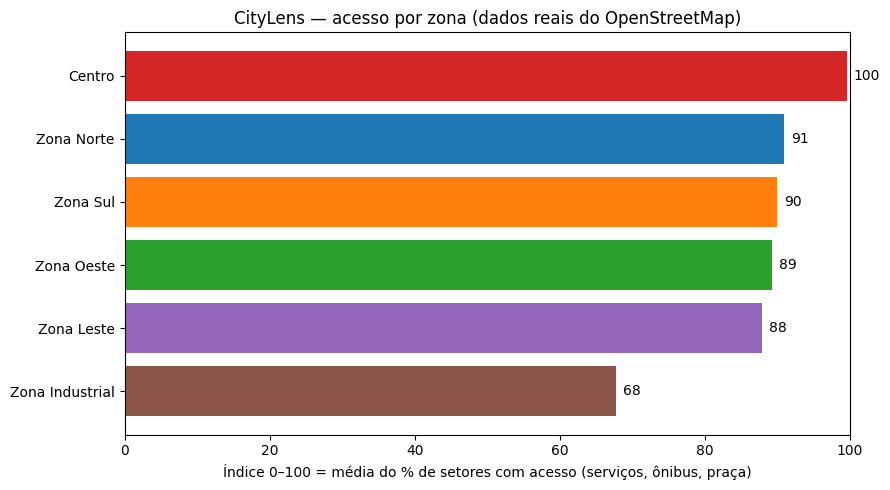

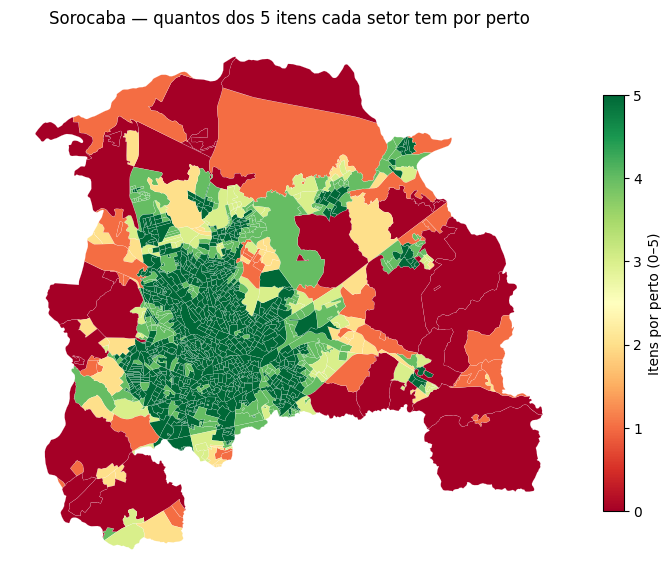


CSVs salvos: /content/indicadores_por_zona_acesso.csv e /content/acesso_por_setor.csv


In [10]:
# 8) Passo 3b — ACESSO a partir de cada setor censitário (versão recomendada)
# Pergunta que respondemos para CADA setor: "o morador daqui tem X por perto?"
# A nota da zona = % dos setores da zona que têm acesso (setores ≈ mesma população,
# então isso ≈ % dos moradores). É uma nota ABSOLUTA (0–100 %), sem min–máx:
# não depende do tamanho da zona e diferenças pequenas continuam pequenas.
import pandas as pd, numpy as np, geopandas as gpd, matplotlib.pyplot as plt

M = 31983  # SIRGAS 2000 / UTM 23S (metros)
RAIOS = {            # distância a pé considerada "perto" (referências usuais de urbanismo)
    "onibus":   400, # parada de ônibus a até 400 m (~5 min a pé)
    "comercio": 500, # mercado/padaria/farmácia a até 500 m
    "saude":   1000, # posto/clínica/hospital a até 1 km
    "escolas": 1000, # escola/creche a até 1 km
    "parques":  500, # praça/parque a até 500 m (sem reservas naturais)
}

cent = gpd.GeoDataFrame(setores[["CD_SETOR", "zona"]].copy(),
                        geometry=setores.to_crs(M).geometry.centroid, crs=M)

def feicoes(cat):
    g = gdfs.get(cat)
    if g is None or len(g) == 0:
        return gpd.GeoDataFrame(geometry=[], crs=M)
    g = g.to_crs(M)
    if cat == "parques":
        # reservas/áreas naturais grandes (rurais) não contam como praça do bairro
        if "leisure" in g.columns:
            g = g[g["leisure"].astype(str) != "nature_reserve"]
        return g[["geometry"]]                      # distância até a borda do parque
    return gpd.GeoDataFrame(geometry=g.geometry.representative_point(), crs=M)

acesso = pd.DataFrame({"CD_SETOR": cent["CD_SETOR"], "zona": cent["zona"]})
for cat, r in RAIOS.items():
    f = feicoes(cat)
    if len(f) == 0:
        acesso[cat] = 0; continue
    buf = gpd.GeoDataFrame(cent[["CD_SETOR"]], geometry=cent.buffer(r), crs=M)
    j = gpd.sjoin(buf, f, predicate="intersects", how="inner")
    acesso[cat] = acesso["CD_SETOR"].isin(set(j["CD_SETOR"])).astype(int)

# % de setores com acesso, por zona
pct = acesso.groupby("zona")[list(RAIOS)].mean().mul(100).reindex(ordem)
pct["setores"] = acesso.groupby("zona").size().reindex(ordem)
pct["servicos"]   = pct[["saude", "escolas", "comercio"]].mean(axis=1)
pct["mobilidade"] = pct["onibus"]
pct["ambiente"]   = pct["parques"]
pct["indice"]     = pct[["servicos", "mobilidade", "ambiente"]].mean(axis=1)
pct["zona_nome"]  = [ZONAS[z]["nome"] for z in pct.index]
res = pct.sort_values("indice", ascending=False)

print("% dos setores (≈ % dos moradores) com cada coisa por perto:\n")
cols = ["zona_nome", "setores", "onibus", "comercio", "saude", "escolas", "parques",
        "servicos", "mobilidade", "ambiente", "indice"]
print(res[cols].round(0).astype({c: int for c in cols[1:]}).to_string(index=False))
print("\nRaios:", ", ".join(f"{k} {v} m" for k, v in RAIOS.items()))

# cidade toda (referência)
geral = acesso[list(RAIOS)].mean().mul(100).round(0)
print("Sorocaba inteira:", ", ".join(f"{k} {int(v)}%" for k, v in geral.items()))

res.reset_index().to_csv("/content/indicadores_por_zona_acesso.csv", index=False)
acesso.to_csv("/content/acesso_por_setor.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(res["zona_nome"], res["indice"], color=[CORES[z] for z in res.index])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Índice 0–100 = média do % de setores com acesso (serviços, ônibus, praça)")
ax.set_title("CityLens — acesso por zona (dados reais do OpenStreetMap)")
for i, v in enumerate(res["indice"]): ax.text(v + 1, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

# mapa: quantos dos 5 itens cada setor tem por perto
setores["n_acesso"] = setores["CD_SETOR"].map(acesso.set_index("CD_SETOR")[list(RAIOS)].sum(axis=1))
fig, ax = plt.subplots(figsize=(9, 9))
setores.plot(column="n_acesso", cmap="RdYlGn", vmin=0, vmax=5, linewidth=0.1,
             edgecolor="white", legend=True, ax=ax,
             legend_kwds={"label": "Itens por perto (0–5)", "shrink": 0.6})
ax.set_title("Sorocaba — quantos dos 5 itens cada setor tem por perto")
ax.set_axis_off(); plt.show()

print("\nCSVs salvos: /content/indicadores_por_zona_acesso.csv e /content/acesso_por_setor.csv")


Praças/parques usados (sem reserva natural e sem 'garden'): 1263

Nota 0–100 por item (média dos setores da zona):

      zona_nome  setores  onibus  comercio  saude  escolas  parques  servicos  mobilidade  ambiente  indice
         Centro       24     100        95    100      100      100        98         100       100      99
     Zona Norte      543      92        75     90       93       95        86          92        95      91
       Zona Sul      127      91        77     93       81       95        84          91        95      90
     Zona Oeste      240      91        75     87       87       91        83          91        91      88
     Zona Leste      105      90        60     89       89       96        79          90        96      88
Zona Industrial      109      70        43     68       75       76        62          70        76      69

Distância MEDIANA (m) do setor até o item mais próximo:

                 onibus  comercio  saude  escolas  parques
Centro     

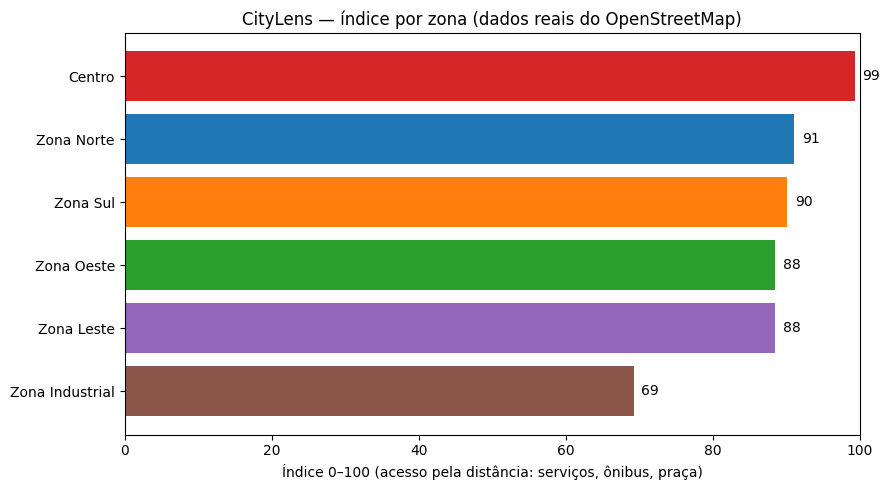

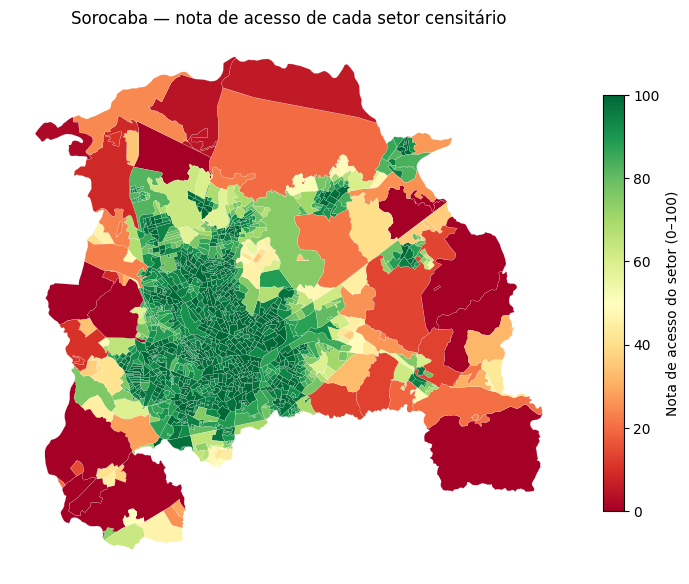


CSVs: /content/indicadores_por_zona_final.csv e /content/acesso_por_setor_final.csv


In [11]:
# 9) Passo 3c — ACESSO com nota pela DISTÂNCIA (versão final recomendada)
# Para cada setor medimos a distância (em linha reta, do centro do setor) até o item
# mais próximo de cada categoria. Nota do item: 100 se está "bem perto" (D0),
# cai em linha reta até 0 quando fica "longe demais" (D1). A nota da zona é a média
# dos setores (setores ≈ mesma população ⇒ ≈ média por morador). Nota absoluta, sem min–máx.
# Praças: sem reservas naturais e sem "garden" (no OSM muitos são jardins privados).
import pandas as pd, numpy as np, geopandas as gpd, matplotlib.pyplot as plt

M = 31983  # SIRGAS 2000 / UTM 23S (metros)
FAIXAS = {             # (D0 = nota 100, D1 = nota 0), em metros
    "onibus":   (200,  800),
    "comercio": (250, 1000),
    "saude":    (500, 2000),
    "escolas":  (500, 1500),
    "parques":  (250, 1000),
}

cent = gpd.GeoDataFrame(setores[["CD_SETOR", "zona"]].copy(),
                        geometry=setores.to_crs(M).geometry.centroid, crs=M)

def feicoes(cat):
    g = gdfs.get(cat)
    if g is None or len(g) == 0:
        return gpd.GeoDataFrame(geometry=[], crs=M)
    g = g.to_crs(M)
    if cat == "parques":
        if "leisure" in g.columns:
            g = g[~g["leisure"].astype(str).isin(["nature_reserve", "garden"])]
        return gpd.GeoDataFrame(geometry=g.geometry.values, crs=M)   # distância até a borda
    return gpd.GeoDataFrame(geometry=g.geometry.representative_point().values, crs=M)

dist = pd.DataFrame({"CD_SETOR": cent["CD_SETOR"].values, "zona": cent["zona"].values})
nota = dist.copy()
for cat, (d0, d1) in FAIXAS.items():
    f = feicoes(cat)
    if len(f) == 0:
        dist[cat] = np.inf; nota[cat] = 0.0
        print(f"aviso: {cat} sem dados no OSM -> nota 0"); continue
    j = gpd.sjoin_nearest(cent[["CD_SETOR", "geometry"]], f, how="left", distance_col="d")
    d = j.groupby("CD_SETOR")["d"].min()
    dist[cat] = dist["CD_SETOR"].map(d).values
    nota[cat] = (np.clip((d1 - dist[cat]) / (d1 - d0), 0, 1) * 100).values
print(f"Praças/parques usados (sem reserva natural e sem 'garden'): {len(feicoes('parques'))}")

# nota por zona = média dos setores
Z = nota.groupby("zona")[list(FAIXAS)].mean().reindex(ordem)
Z["servicos"]   = Z[["saude", "escolas", "comercio"]].mean(axis=1)
Z["mobilidade"] = Z["onibus"]
Z["ambiente"]   = Z["parques"]
Z["indice"]     = Z[["servicos", "mobilidade", "ambiente"]].mean(axis=1)
Z["setores"]    = nota.groupby("zona").size().reindex(ordem)
Z["zona_nome"]  = [ZONAS[z]["nome"] for z in Z.index]
res = Z.sort_values("indice", ascending=False)

print("\nNota 0–100 por item (média dos setores da zona):\n")
cols = ["zona_nome", "setores", "onibus", "comercio", "saude", "escolas", "parques",
        "servicos", "mobilidade", "ambiente", "indice"]
print(res[cols].round(0).astype({c: int for c in cols[1:]}).to_string(index=False))

med = dist.groupby("zona")[list(FAIXAS)].median().reindex(ordem).round(0)
med.index = [ZONAS[z]["nome"] for z in med.index]
print("\nDistância MEDIANA (m) do setor até o item mais próximo:\n")
print(med.astype(int).to_string())
print("\nFaixas (nota 100 → nota 0):", ", ".join(f"{k} {a}–{b} m" for k, (a, b) in FAIXAS.items()))

res.reset_index().to_csv("/content/indicadores_por_zona_final.csv", index=False)
dist.merge(nota, on=["CD_SETOR", "zona"], suffixes=("_dist_m", "_nota")) \
    .to_csv("/content/acesso_por_setor_final.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(res["zona_nome"], res["indice"], color=[CORES[z] for z in res.index])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Índice 0–100 (acesso pela distância: serviços, ônibus, praça)")
ax.set_title("CityLens — índice por zona (dados reais do OpenStreetMap)")
for i, v in enumerate(res["indice"]): ax.text(v + 1, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

setores["nota_acesso"] = setores["CD_SETOR"].map(
    nota.set_index("CD_SETOR")[list(FAIXAS)].mean(axis=1))
fig, ax = plt.subplots(figsize=(9, 9))
setores.plot(column="nota_acesso", cmap="RdYlGn", vmin=0, vmax=100, linewidth=0.1,
             edgecolor="white", legend=True, ax=ax,
             legend_kwds={"label": "Nota de acesso do setor (0–100)", "shrink": 0.6})
ax.set_title("Sorocaba — nota de acesso de cada setor censitário")
ax.set_axis_off(); plt.show()

print("\nCSVs: /content/indicadores_por_zona_final.csv e /content/acesso_por_setor_final.csv")


Baixando a malha de ruas para pedestres de Sorocaba (OSM)...
  22,327 nós · 63,732 trechos · 125s
  onibus   : distância a pé calculada (1626 destinos na rede)
  comercio : distância a pé calculada (325 destinos na rede)
  saude    : distância a pé calculada (262 destinos na rede)
  escolas  : distância a pé calculada (307 destinos na rede)
  parques  : distância a pé calculada (5487 destinos na rede)

Pronto em 127s.

CAMINHABILIDADE por zona (0–100):

      zona_nome  conectividade  dez_min  caminhabilidade
         Centro            100       98               99
     Zona Norte             79       80               79
     Zona Leste             82       74               78
     Zona Oeste             77       74               76
       Zona Sul             71       73               72
Zona Industrial             40       48               44

ÍNDICE FINAL com 4 eixos (distâncias A PÉ pela rua):

      zona_nome  servicos  mobilidade  ambiente  caminhabilidade  indice
         Centro

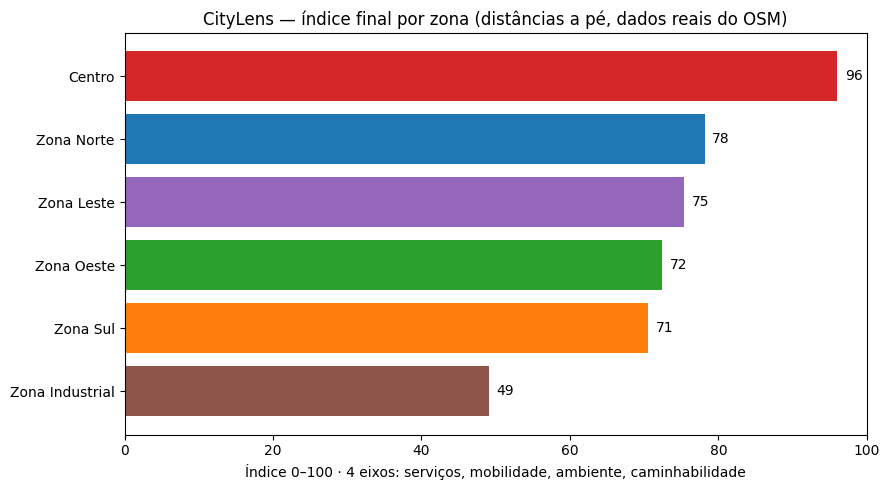

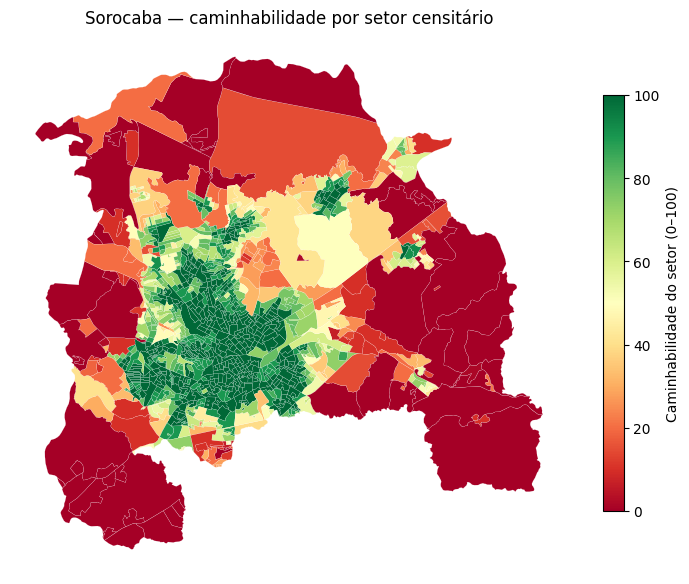


CSVs: /content/indice_final_4eixos.csv e /content/caminhabilidade_por_setor.csv


In [12]:
# 10) Passo 4 — CAMINHABILIDADE com a malha de ruas real (OpenStreetMap)
# Baixa todas as ruas/calçadas/caminhos de pedestre de Sorocaba e mede, para cada setor:
#  (a) DISTÂNCIA A PÉ pela rua (não mais em linha reta) até ônibus, comércio, saúde, escola, praça;
#  (b) CONECTIVIDADE: cruzamentos por km² num raio de 500 m (quarteirão pequeno = mais fácil andar);
#  (c) "CIDADE DE 10 MINUTOS": quantos dos 5 itens estão a até 800 m a pé (~10 min).
# Caminhabilidade = média de (b) e (c). Os outros 3 eixos passam a usar a distância a pé.
# Pode levar 3–8 min (download da malha). Não inventa dado: tudo vem do OSM.
import osmnx as ox, networkx as nx, numpy as np, pandas as pd, geopandas as gpd, time
import matplotlib.pyplot as plt

M = 31983
t0 = time.time()
print("Baixando a malha de ruas para pedestres de Sorocaba (OSM)...")
G = ox.graph_from_polygon(SORO_POLY, network_type="walk", simplify=True)
Gp = ox.project_graph(G, to_crs=f"EPSG:{M}")
Gu = Gp.to_undirected()
nos = ox.graph_to_gdfs(Gp, edges=False)
print(f"  {len(nos):,} nós · {Gp.number_of_edges():,} trechos · {time.time()-t0:.0f}s")

# setores -> nó da rede mais próximo (+ a distância até chegar na rua)
cent = gpd.GeoDataFrame(setores[["CD_SETOR", "zona"]].copy(),
                        geometry=setores.to_crs(M).geometry.centroid, crs=M)
no_set, d_snap = ox.distance.nearest_nodes(Gp, cent.geometry.x.values, cent.geometry.y.values,
                                           return_dist=True)
cent["no"], cent["snap"] = no_set, d_snap

def fontes(cat):
    """Nós da rede que 'são' o destino: nó mais próximo de cada ponto (+ entradas de parques)."""
    g = gdfs.get(cat)
    if g is None or len(g) == 0:
        return set()
    g = g.to_crs(M)
    if cat == "parques" and "leisure" in g.columns:
        g = g[~g["leisure"].astype(str).isin(["nature_reserve", "garden"])]
    rp = g.geometry.representative_point()
    src = set(ox.distance.nearest_nodes(Gp, rp.x.values, rp.y.values))
    if cat == "parques":   # parque grande: qualquer nó a até 30 m da borda conta como entrada
        pol = g[g.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
        if len(pol):
            b = gpd.GeoDataFrame(geometry=pol.geometry.buffer(30).values, crs=M)
            src |= set(gpd.sjoin(nos[["geometry"]], b, predicate="within").index)
    return src

CORTE = 5000  # para de procurar depois de 5 km a pé
dist_pe = pd.DataFrame({"CD_SETOR": cent["CD_SETOR"].values, "zona": cent["zona"].values})
for cat in FAIXAS:
    src = fontes(cat)
    if not src:
        dist_pe[cat] = np.inf; print(f"  {cat}: sem dados"); continue
    L = nx.multi_source_dijkstra_path_length(Gu, src, cutoff=CORTE, weight="length")
    dist_pe[cat] = [L.get(n, np.inf) + s for n, s in zip(cent["no"], cent["snap"])]
    print(f"  {cat:9s}: distância a pé calculada ({len(src)} destinos na rede)")

# notas por item com a distância A PÉ (mesmas faixas do passo 3c)
nota_pe = dist_pe[["CD_SETOR", "zona"]].copy()
for cat, (d0, d1) in FAIXAS.items():
    nota_pe[cat] = np.clip((d1 - dist_pe[cat]) / (d1 - d0), 0, 1) * 100

# (b) conectividade: cruzamentos (3+ ruas) por km² num raio de 500 m do setor
cruz = nos[nos["street_count"] >= 3][["geometry"]]
buf = gpd.GeoDataFrame(cent[["CD_SETOR"]], geometry=cent.buffer(500), crs=M)
n_cruz = gpd.sjoin(cruz, buf, predicate="within").groupby("CD_SETOR").size()
area_buf = np.pi * 0.5**2
dist_pe["cruz_km2"] = dist_pe["CD_SETOR"].map(n_cruz).fillna(0).values / area_buf
C0, C1 = 20, 120   # 20 cruz./km² = nota 0 (rural) · 120 = nota 100 (quarteirões curtos)
nota_pe["conectividade"] = np.clip((dist_pe["cruz_km2"] - C0) / (C1 - C0), 0, 1) * 100

# (c) cidade de 10 minutos: % dos 5 itens a até 800 m a pé
nota_pe["dez_min"] = (dist_pe[list(FAIXAS)] <= 800).mean(axis=1) * 100
nota_pe["caminhabilidade"] = nota_pe[["conectividade", "dez_min"]].mean(axis=1)

# nota por zona (média dos setores) — agora com os 4 eixos
Z4 = nota_pe.groupby("zona")[list(FAIXAS) + ["conectividade", "dez_min", "caminhabilidade"]].mean().reindex(ordem)
Z4["servicos"]   = Z4[["saude", "escolas", "comercio"]].mean(axis=1)
Z4["mobilidade"] = Z4["onibus"]
Z4["ambiente"]   = Z4["parques"]
Z4["indice"]     = Z4[["servicos", "mobilidade", "ambiente", "caminhabilidade"]].mean(axis=1)
Z4["zona_nome"]  = [ZONAS[z]["nome"] for z in Z4.index]
res4 = Z4.sort_values("indice", ascending=False)

print(f"\nPronto em {time.time()-t0:.0f}s.\n\nCAMINHABILIDADE por zona (0–100):\n")
c1 = ["zona_nome", "conectividade", "dez_min", "caminhabilidade"]
print(res4[c1].round(0).astype({c: int for c in c1[1:]}).to_string(index=False))

print("\nÍNDICE FINAL com 4 eixos (distâncias A PÉ pela rua):\n")
c2 = ["zona_nome", "servicos", "mobilidade", "ambiente", "caminhabilidade", "indice"]
print(res4[c2].round(0).astype({c: int for c in c2[1:]}).to_string(index=False))

medpe = dist_pe.groupby("zona")[list(FAIXAS) + ["cruz_km2"]].median().reindex(ordem).round(0)
medpe.index = [ZONAS[z]["nome"] for z in medpe.index]
print("\nDistância MEDIANA A PÉ (m) e cruzamentos/km²:\n")
print(medpe.replace(np.inf, np.nan).fillna(-1).astype(int).to_string())

# quanto a rua 'estica' o caminho em relação à linha reta (mediana, cidade toda)
fator = (dist_pe[list(FAIXAS)] / dist[list(FAIXAS)].replace(0, np.nan)).replace(np.inf, np.nan)
print("\nA pé é, em mediana, este tanto mais longe que em linha reta:",
      ", ".join(f"{k} ×{v:.2f}" for k, v in fator.median().items()))

res4.reset_index().to_csv("/content/indice_final_4eixos.csv", index=False)
dist_pe.merge(nota_pe, on=["CD_SETOR", "zona"], suffixes=("_m", "_nota")) \
       .to_csv("/content/caminhabilidade_por_setor.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(res4["zona_nome"], res4["indice"], color=[CORES[z] for z in res4.index])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Índice 0–100 · 4 eixos: serviços, mobilidade, ambiente, caminhabilidade")
ax.set_title("CityLens — índice final por zona (distâncias a pé, dados reais do OSM)")
for i, v in enumerate(res4["indice"]): ax.text(v + 1, i, f"{v:.0f}", va="center")
plt.tight_layout(); plt.show()

setores["caminhabilidade"] = setores["CD_SETOR"].map(nota_pe.set_index("CD_SETOR")["caminhabilidade"])
fig, ax = plt.subplots(figsize=(9, 9))
setores.plot(column="caminhabilidade", cmap="RdYlGn", vmin=0, vmax=100, linewidth=0.1,
             edgecolor="white", legend=True, ax=ax,
             legend_kwds={"label": "Caminhabilidade do setor (0–100)", "shrink": 0.6})
ax.set_title("Sorocaba — caminhabilidade por setor censitário")
ax.set_axis_off(); plt.show()
print("\nCSVs: /content/indice_final_4eixos.csv e /content/caminhabilidade_por_setor.csv")


In [13]:
print(res4[['zona_nome','saude','escolas','comercio','onibus','parques','conectividade','dez_min']].round(1).to_string(index=False))

      zona_nome  saude  escolas  comercio  onibus  parques  conectividade  dez_min
         Centro   99.8     99.9      82.1    93.1     97.9          100.0     98.3
     Zona Norte   77.2     81.5      55.3    77.7     84.3           78.5     80.1
     Zona Leste   72.9     79.5      36.9    75.4     85.4           81.8     73.5
     Zona Oeste   70.5     71.4      55.0    73.2     75.3           76.9     74.2
       Zona Sul   76.5     62.0      51.2    67.9     78.8           71.2     73.2
Zona Industrial   46.0     50.9      24.0    49.3     62.7           39.7     48.4
